In [3]:
%pip install seaborn

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

In [13]:
from js import fetch
import io

URL = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv'
resp = await fetch(URL)
boston_url = io.BytesIO((await resp.arrayBuffer()).to_py())

In [14]:
boston_df = pd.read_csv(boston_url)

In [15]:
boston_df.head()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


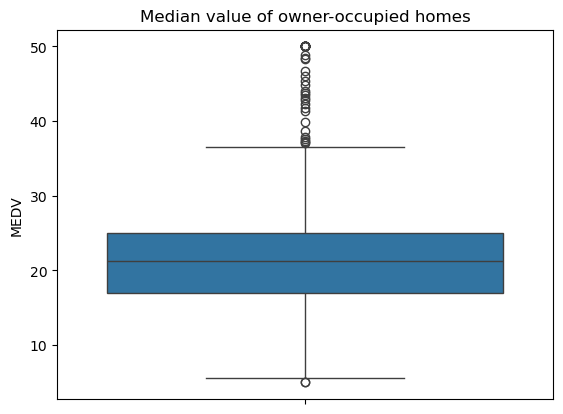

In [16]:
sns.boxplot(y='MEDV', data=boston_df)
plt.title('Median value of owner-occupied homes')
plt.show()


CHAS
0.0    22.093843
1.0    28.440000
Name: MEDV, dtype: float64


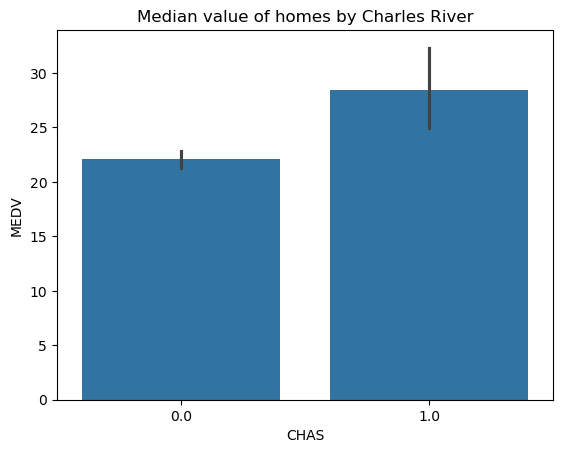

In [17]:
print(boston_df.groupby('CHAS')['MEDV'].mean())

sns.barplot(x='CHAS', y='MEDV', data=boston_df)
plt.title('Median value of homes by Charles River')
plt.xlabel('CHAS')
plt.ylabel('MEDV')
plt.show()

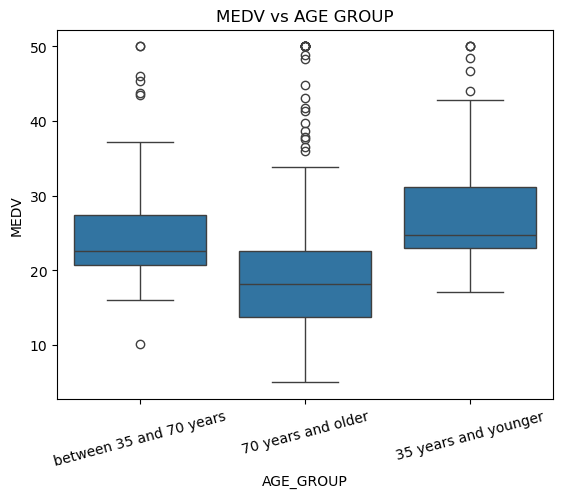

In [18]:
boston_df.loc[boston_df['AGE'] <= 35, 'AGE_GROUP'] = '35 years and younger'
boston_df.loc[(boston_df['AGE'] > 35) & (boston_df['AGE'] <= 70), 'AGE_GROUP'] = 'between 35 and 70 years'
boston_df.loc[boston_df['AGE'] > 70, 'AGE_GROUP'] = '70 years and older'

sns.boxplot(x='AGE_GROUP', y='MEDV', data=boston_df)
plt.title('MEDV vs AGE GROUP')
plt.xticks(rotation=15)
plt.show()

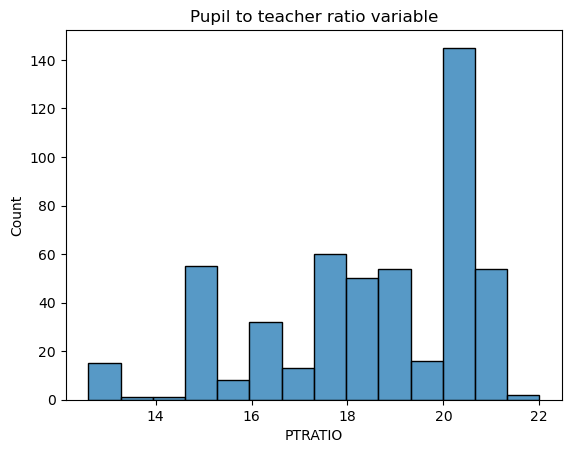

In [19]:
sns.histplot(data=boston_df, x='PTRATIO')
plt.title('Pupil to teacher ratio variable')
plt.show()

In [20]:
result = scipy.stats.ttest_ind(
    boston_df[boston_df['CHAS'] == 0]['MEDV'],
    boston_df[boston_df['CHAS'] == 1]['MEDV'],
    equal_var=True
)

print(result)

TtestResult(statistic=np.float64(-3.996437466090509), pvalue=np.float64(7.390623170519907e-05), df=np.float64(504.0))


In [21]:
thirty_five_younger = boston_df[
    boston_df['AGE_GROUP'] == '35 years and younger'
]['MEDV']

thirty_five_seventy = boston_df[
    boston_df['AGE_GROUP'] == 'between 35 and 70 years'
]['MEDV']

seventy_older = boston_df[
    boston_df['AGE_GROUP'] == '70 years and older'
]['MEDV']

f_statistic, p_value = scipy.stats.f_oneway(
    thirty_five_younger,
    thirty_five_seventy,
    seventy_older
)

print("F_Statistic:", f_statistic)
print("P-Value:", p_value)

F_Statistic: 36.407649991965926
P-Value: 1.7105011022702497e-15


In [ ]:
lm = ols('MEDV ~ AGE', data=boston_df).fit()

table = sm.stats.anova_lm(lm)

print(table)

In [22]:
correlation, p_value = scipy.stats.pearsonr(
    boston_df['INDUS'],
    boston_df['NOX']
)

print("Correlation:", correlation)
print("P-Value:", p_value)

Correlation: 0.7636514469209181
P-Value: 7.913361061218657e-98


In [23]:
x = boston_df['DIS']
y = boston_df['MEDV']

x = sm.add_constant(x)

model = sm.OLS(y, x).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Sat, 29 Aug 2026   Prob (F-statistic):           1.21e-08
Time:                        22:16:42   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.0